# 04 — Socioeconomic context: ACS 2020–2024 × FCC availability

Tract-level FCC aggregates (notebook 03) joined to American Community Survey 5-year estimates.

* **Availability** (FCC) counts *locations* where service is reported.
* **Adoption** (ACS B28002) counts *households* that subscribe.
* Correlations are Spearman rank correlations across 193 tracts. They describe associations, not causes, and ACS estimates carry margins of error.

Census data comes from the ACS table-based Summary File (Vermont rows extracted to `data/raw/census/acs5_2024_vt_extract.csv`). See `census.py` for how to rebuild it.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path("..").resolve() / "src"))

import pandas as pd
import matplotlib.pyplot as plt
from vermont_broadband_analysis import census, socioeconomic

pd.set_option("display.width", 160)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
                     "axes.grid": True, "grid.color": "#e1e0d9", "axes.axisbelow": True,
                     "xtick.color": "#898781", "ytick.color": "#898781", "axes.labelcolor": "#52514e",
                     "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb"})

## 1. Load ACS and validate

In [2]:
acs = census.run()
tract, county = acs["tract"], acs["county"]
print("State population (tracts):", f"{tract.population.sum():,.0f}")
county[["county_fips", "population", "median_household_income", "pct_hh_broadband", "pct_hh_no_internet", "pct_below_poverty"]]

ACS tracts: 193, counties: 14
State population (tracts): 647,106


,county_fips,population,median_household_income,pct_hh_broadband,pct_hh_no_internet,pct_below_poverty
0,50001,37664.0,89639.0,91.43,5.49,7.58
1,50003,37269.0,73325.0,84.43,8.47,11.33
2,50005,30475.0,69970.0,86.39,11.07,11.72
3,50007,169758.0,96759.0,93.44,3.31,9.73
4,50009,5982.0,59294.0,86.08,11.83,13.85
5,50011,50638.0,81313.0,89.48,7.49,10.27
6,50013,7450.0,97396.0,92.48,4.39,7.94
7,50015,26148.0,74908.0,91.87,5.56,8.51
8,50017,29761.0,82232.0,88.35,7.40,9.31
9,50019,27606.0,70103.0,89.02,8.73,11.73


## 2. Join and correlate

In [3]:
tables = socioeconomic.run()
joined = tables["tract_fcc_acs"]
print(len(joined), "tracts joined")
tables["spearman_fcc_vs_acs"]

                           median_household_income  pop_per_sqmi  pct_below_poverty  median_age  pct_hh_broadband  pct_hh_no_internet
pct_served                                  -0.059         0.726              0.181      -0.303             0.160              -0.264
pct_unserved                                 0.012        -0.766             -0.151       0.328            -0.192               0.278
pct_no_wired_100_20                          0.067        -0.721             -0.194       0.309            -0.152               0.256
pct_two_plus_wired_100_20                   -0.189         0.563              0.291      -0.253             0.102              -0.151
pct_has_fiber                               -0.154         0.186              0.203      -0.134             0.029              -0.075
                        median_household_income  pop_per_sqmi  pct_below_poverty  median_age  pct_served
pct_hh_broadband                          0.347         0.201             -0.236      -0.12

,fcc_metric,median_household_income,pop_per_sqmi,pct_below_poverty,median_age,pct_hh_broadband,pct_hh_no_internet
0,pct_served,-0.059,0.726,0.181,-0.303,0.160,-0.264
1,pct_unserved,0.012,-0.766,-0.151,0.328,-0.192,0.278
2,pct_no_wired_100_20,0.067,-0.721,-0.194,0.309,-0.152,0.256
3,pct_two_plus_wired_100_20,-0.189,0.563,0.291,-0.253,0.102,-0.151
4,pct_has_fiber,-0.154,0.186,0.203,-0.134,0.029,-0.075


Availability tracks **density** (ρ ≈ 0.73 for served share) and is essentially unrelated to **income** (ρ ≈ −0.06).

In [4]:
tables["spearman_adoption"]

,adoption_metric,median_household_income,pop_per_sqmi,pct_below_poverty,median_age,pct_served
0,pct_hh_broadband,0.347,0.201,-0.236,-0.122,0.160
1,pct_hh_wired_broadband,0.332,0.389,-0.115,-0.076,0.480
2,pct_hh_no_internet,-0.357,-0.257,0.279,0.077,-0.264
3,pct_hh_no_computer,-0.336,-0.250,0.259,0.086,-0.219


Adoption is the reverse: household broadband subscription rises with **income** (ρ ≈ 0.35) and falls with poverty.

## 3. Density

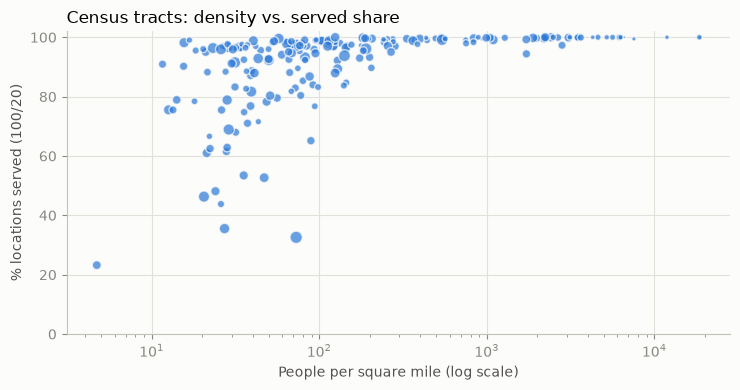

In [5]:
fig, ax = plt.subplots(figsize=(7.5, 4))
t = joined[(joined.locations >= 50) & (joined.pop_per_sqmi > 0)]
ax.scatter(t.pop_per_sqmi, t.pct_served, s=t.locations / 40, color="#2a78d6", alpha=.7, edgecolor="#fcfcfb", linewidth=1)
ax.set_xscale("log"); ax.set_ylim(0, 102)
ax.set_xlabel("People per square mile (log scale)"); ax.set_ylabel("% locations served (100/20)")
ax.set_title("Census tracts: density vs. served share", loc="left"); plt.tight_layout()

In [6]:
tables["access_by_density_class"][["density_class", "tracts", "locations", "pct_served", "pct_unserved", "pct_no_wired_100_20", "pct_hh_broadband", "pct_hh_wired_broadband"]]

,density_class,tracts,locations,pct_served,pct_unserved,pct_no_wired_100_20,pct_hh_broadband,pct_hh_wired_broadband
0,Very rural (<50/sq mi),64,100755,80.61,10.14,20.33,88.58,71.00
1,Rural (50-200),69,111226,92.08,3.01,8.55,89.24,76.60
2,"Small town (200-1,000)",28,35569,98.47,0.80,1.73,92.25,81.71
3,"Urban (>1,000)",32,34827,99.48,0.18,0.59,90.20,78.72


## 4. Income: availability vs. adoption

In [7]:
inc = tables["access_by_income_quartile"]
inc[["income_quartile", "tracts", "median_income", "pct_served", "pct_no_wired_100_20", "pct_hh_broadband", "pct_hh_wired_broadband"]]

,income_quartile,tracts,median_income,pct_served,pct_no_wired_100_20,pct_hh_broadband,pct_hh_wired_broadband
0,Q1 (lowest),49,61161.0,89.78,10.87,87.74,73.80
1,Q2,47,75156.0,85.44,15.20,88.29,73.38
2,Q3,48,86109.5,88.73,11.98,89.80,75.74
3,Q4 (highest),48,107369.5,94.42,6.05,92.88,82.13


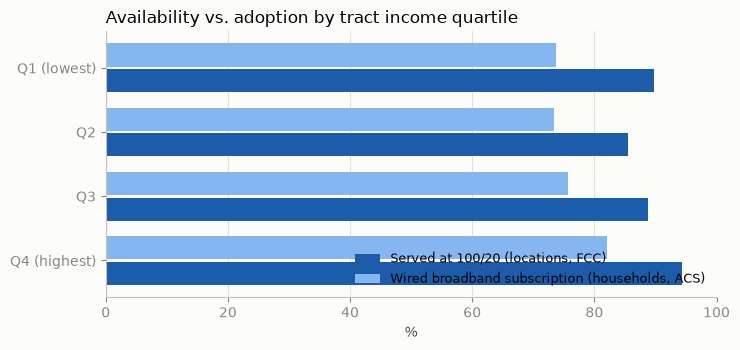

In [8]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
y = range(len(inc))
ax.barh([i + 0.2 for i in y], inc.pct_served, height=0.36, color="#1c5cab", label="Served at 100/20 (locations, FCC)")
ax.barh([i - 0.2 for i in y], inc.pct_hh_wired_broadband, height=0.36, color="#86b6ef", label="Wired broadband subscription (households, ACS)")
ax.set_yticks(list(y), inc.income_quartile); ax.invert_yaxis(); ax.set_xlim(0, 100); ax.grid(axis="y", visible=False)
ax.set_xlabel("%"); ax.legend(loc="lower right", frameon=False, fontsize=9)
ax.set_title("Availability vs. adoption by tract income quartile", loc="left"); plt.tight_layout()

## 5. Tracts to watch
Low availability **and** low adoption: candidates for both infrastructure and affordability programs.

In [9]:
watch = joined[(joined.locations >= 100)].assign(
    gap_score=lambda d: (100 - d.pct_served).rank(pct=True) + (100 - d.pct_hh_broadband).rank(pct=True))
watch.nlargest(10, "gap_score")[["tract_geoid", "county_name", "locations", "pct_served", "pct_unserved",
                                 "pct_hh_broadband", "median_household_income", "pop_per_sqmi"]]

,tract_geoid,county_name,locations,pct_served,pct_unserved,pct_hh_broadband,median_household_income,pop_per_sqmi
163,50025967700,Windham,1019,83.22,5.30,74.94,79706.0,98.4
108,50019951300,Orleans,1002,76.75,14.67,81.54,80729.0,94.0
160,50025967400,Windham,978,78.43,16.26,81.43,79219.0,18.0
29,50005957700,Caledonia,1377,80.39,5.52,80.87,92297.0,77.5
24,50005957200,Caledonia,1124,84.70,2.05,76.43,76250.0,144.7
162,50025967600,Windham,1379,88.11,6.82,74.14,71491.0,66.6
75,50009950500,Essex,2131,75.55,9.62,83.85,62207.0,12.6
25,50005957300,Caledonia,1057,83.73,3.03,81.56,68621.0,140.2
23,50005957100,Caledonia,1205,74.77,4.90,84.24,81932.0,35.6
161,50025967500,Windham,1348,75.52,10.91,84.21,82083.0,13.4


## 6. Takeaways
* **Rurality limits access.** Very rural tracts (< 50 people/sq mi) are 80.6% served and 10.1% unserved; small-town and urban tracts are above 98%.
* **Income limits adoption.** Availability is similar across the lower three income quartiles (85–90% served), but wired subscription is 73–76% there versus 82% in the top quartile.
* Policy implication (descriptive): remaining infrastructure gaps are a rural build-out problem, while lower adoption in lower-income tracts points to affordability programs.
* Caveats: ecological data (tracts, not households), ACS sampling error, and availability counts locations while adoption counts households.